In [51]:
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START,END 
from typing import TypedDict 
from dotenv import load_dotenv
load_dotenv()

True

In [71]:
# define state 
class LLMState(TypedDict):
    topic: str
    outline: str
    blog: str
    

In [74]:
#define graph 
graph = StateGraph(LLMState)


In [56]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",  # Or use "qwen/qwen3.8-27b"
    temperature=0
)


In [57]:
llm.invoke("Hello, how are you?").content

"Hello! I'm doing great, thank you for asking. How can I assist you today?"

In [73]:
def generate_outline(state: LLMState) -> LLMState:
    #define the model 
    topic = state['topic']
    prompt = f"Generate an outline for a blog post about {topic}:"
    outline = llm.invoke(prompt).content
    state['outline'] = outline
    return state

In [72]:
def generate_blog(state: LLMState) -> LLMState:
    outline = state['outline']
    topic = state['topic']
    prompt = f"Generate a blog post based on the following outline:\n{outline} and on the topic {topic}"
    blog = llm.invoke(prompt).content
    state['blog'] = blog
    return state

In [75]:
#define nodes, edges and compile workflow 
graph.add_node('generate_outline', generate_outline)
graph.add_node('generate_blog', generate_blog)
#edges 
graph.add_edge(START, 'generate_outline')
graph.add_edge('generate_outline', 'generate_blog')
graph.add_edge('generate_blog', END)

workflow = graph.compile()

In [76]:
initial_state = LLMState(topic="Narendra Modi", outline="", blog="")
final_state = workflow.invoke(initial_state)
print(final_state)

{'topic': 'Narendra Modi', 'outline': '**Title:** *Narendra Modi: A Comprehensive Look at India’s Prime Minister and His Impact on the Nation*\n\n---\n\n### 1. Introduction  \n- Brief hook: Why Modi remains a pivotal figure in contemporary global politics.  \n- Purpose of the post: To provide readers with a balanced overview of his life, political journey, policies, and legacy.  \n- Scope disclaimer: Focus on publicly documented facts and widely reported analyses.\n\n### 2. Early Life and Background  \n- Birth and family origins (Gujarat, 1950).  \n- Education and early influences.  \n- Early involvement in the Rashtriya Swayamsevak Sangh (RSS).  \n\n### 3. Political Rise  \n- Entry into the Bharatiya Janata Party (BJP).  \n- Key roles within the party (e.g., General Secretary, National Secretary).  \n- 2001–2014: Tenure as Chief Minister of Gujarat – major initiatives and controversies.  \n\n### 4. Ascension to Prime Ministership  \n- 2014 general election: Campaign strategy (“Achhe D

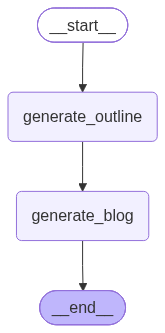

In [77]:
workflow